# NumPy CNN으로 시선 방향 학습하기
눈 이미지와 머리 방향을 함께 사용해 시선의 **yaw, pitch(라디안)**를 예측합니다.

- **딥러닝 계산은 NumPy만 사용**합니다. CNN, 역전파, AdamW를 직접 구현합니다.
- OpenCV는 이미지 읽기, pandas는 표, matplotlib은 그래프에만 사용합니다.
- p00~p14를 한 명씩 테스트하는 **15-fold leave-one-person-out** 평가입니다.
- 성능은 **평균 각도 오차(°)**로 표시하며, **작을수록 좋습니다**. 실제 성능은 실행 후 확인합니다.
- 셀을 위에서 아래로 실행하세요. NumPy CPU 학습이므로 전체 15-fold에는 긴 시간이 걸릴 수 있습니다.


## 1. 실행에 필요한 도구를 준비하는 셀
학습에는 NumPy를, 데이터 읽기와 결과 표시에는 보조 도구를 준비합니다.
설치가 필요하면 아래 첫 줄의 `#`을 지우고 실행한 뒤 커널을 재시작하세요.


In [1]:
# %pip install numpy opencv-python pandas matplotlib

import os
# NumPy를 처음 불러오기 전에 설정합니다. 이미 불러왔다면 커널 재시작 후 적용됩니다.
# 작은 행렬 연산에서 지나치게 많은 CPU 스레드를 사용하는 일을 줄입니다.
for key in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS",
            "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(key, "4")

import json
import hashlib
import time
import sys
from pathlib import Path

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi":110, "axes.grid":True, "grid.alpha":0.25})
print("NumPy:", np.__version__, "| 학습 장치: CPU")


NumPy: 2.5.4 | 학습 장치: CPU


## 2. 데이터 경로와 학습 조건을 정하는 셀
`data/EyeBased/MPIIGaze/Image`와 `Label`을 자동으로 찾습니다.
모든 fold에 같은 모델과 학습 조건을 사용합니다. 테스트 결과를 보고 fold별 설정을 바꾸지 않습니다.

완료된 fold는 재실행할 때 불러옵니다. 중간에 중단된 fold는 처음부터 다시 학습합니다.


In [2]:
def find_project_root():
    cwd = Path.cwd().resolve()
    for base in (cwd, *cwd.parents):
        for candidate in (base, base / "gaze_estimation"):
            if (candidate / "reader.py").is_file() and (candidate / "README.md").is_file():
                return candidate
    raise FileNotFoundError("gaze_estimation 폴더에서 노트북을 열어 주세요.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import reader  # 제공된 NumPy 기반 라벨 읽기 함수를 사용합니다.

DATA_ROOT_OVERRIDE = None  # 데이터가 다른 곳에 있으면 "/전체/경로/MPIIGaze"로 지정
DATA_ROOT = (Path(DATA_ROOT_OVERRIDE).expanduser().resolve()
             if DATA_ROOT_OVERRIDE else PROJECT_ROOT / "data/EyeBased/MPIIGaze")
IMAGE_ROOT, LABEL_ROOT = DATA_ROOT / "Image", DATA_ROOT / "Label"
PERSONS = [f"p{k:02d}" for k in range(15)]
FOLDS = PERSONS.copy()  # 최종 제출은 반드시 15명 전체 평가
RESUME_COMPLETED = True

CFG = {
    "seed":42,
    "epochs":40,
    "batch_size":64,
    "learning_rate":1e-3,
    "min_learning_rate":1e-5,
    "warmup_epochs":2,
    "weight_decay":1e-4,
    "gradient_clip":5.0,
    "channels":[16, 32],
    "image_hidden":128,
    "fusion_hidden":64,
    "dropout":0.25,
    "ema_decay":0.99,
    "photometric_augmentation":True,
}
OUTPUT_BASE = PROJECT_ROOT / "outputs/gaze_numpy"
assert CFG["epochs"] > CFG["warmup_epochs"] >= 0
assert CFG["batch_size"] > 0 and 0 <= CFG["dropout"] < 1
assert 0 <= CFG["ema_decay"] < 1
for path in (IMAGE_ROOT, LABEL_ROOT):
    if not path.is_dir():
        raise FileNotFoundError(f"데이터 폴더가 없습니다: {path}")
print("프로젝트:", PROJECT_ROOT)
print("데이터:", DATA_ROOT)
display(pd.DataFrame({"설정":list(CFG), "값":[str(v) for v in CFG.values()]}))


프로젝트: /Users/parkdongjun/Desktop/3-2/딥러닝/gaze_estimation
데이터: /Users/parkdongjun/Desktop/3-2/딥러닝/gaze_estimation/data/EyeBased/MPIIGaze


,설정,값
0,seed,42
1,epochs,40
2,batch_size,64
3,learning_rate,0.001
4,min_learning_rate,1e-05
5,warmup_epochs,2
6,weight_decay,0.0001
7,gradient_clip,5.0
8,channels,"[16, 32]"
9,image_hidden,128


## 3. 데이터를 읽고 입력 형태를 확인하는 셀
15명의 이미지와 라벨을 읽고, 사람별 개수와 눈 이미지 예시를 보여줍니다.
모델에는 **눈 이미지와 2DHead만 입력**하고, **2DGaze를 정답**으로 사용합니다.
오른눈은 이미 전처리되어 있으므로 추가로 좌우 반전하지 않습니다.


,person,samples
0,p00,3000
1,p01,3000
2,p02,3000
3,p03,3000
4,p04,3000
5,p05,3000
6,p06,3000
7,p07,3000
8,p08,3000
9,p09,3000


총 샘플: 45000 | 입력: (1,36,60) + (2,) | 출력: (2,)


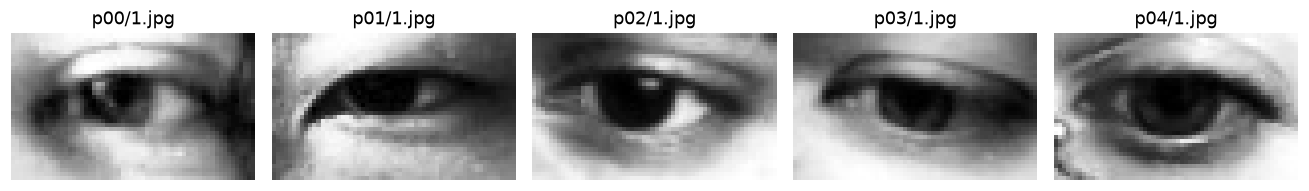

In [3]:
def load_data(data_root, persons):
    image_root, label_root = data_root / "Image", data_root / "Label"
    n = len(persons) * 3000
    # 메모리는 uint8로 보관하고, 모델에 넣을 때 float32 0~1로 바꿉니다.
    images = np.empty((n, 1, 36, 60), dtype=np.uint8)
    heads = np.empty((n, 2), dtype=np.float32)
    gazes = np.empty((n, 2), dtype=np.float32)
    owners, names = [], []
    digest = hashlib.sha256()
    offset = 0
    for person in persons:
        label_path = label_root / f"{person}.label"
        digest.update(person.encode())
        digest.update(label_path.read_bytes())
        rows = reader.read_label(label_path, header=True)
        if len(rows) != 3000:
            raise ValueError(f"{person}: 3,000개가 필요하지만 {len(rows):,}개입니다.")
        for name, gaze_text, head_text in rows:
            rel = Path(name)
            if rel.is_absolute() or ".." in rel.parts or rel.parts[0] != person:
                raise ValueError(f"잘못된 이미지 경로: {name}")
            path = image_root / rel
            raw = path.read_bytes()
            digest.update(name.encode())
            digest.update(raw)
            eye = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_GRAYSCALE)
            if eye is None or eye.shape != (36, 60):
                raise ValueError(f"36×60 이미지가 아닙니다: {path}")
            gaze = np.array(gaze_text.split(","), dtype=np.float32)
            head = np.array(head_text.split(","), dtype=np.float32)
            if gaze.shape != (2,) or head.shape != (2,):
                raise ValueError(f"각도 라벨 형태 오류: {name}")
            if not np.isfinite(gaze).all() or not np.isfinite(head).all():
                raise ValueError(f"각도에 NaN/Inf가 있습니다: {name}")
            images[offset, 0], heads[offset], gazes[offset] = eye, head, gaze
            names.append(name)
            owners.append(person)
            offset += 1
    if len(set(names)) != n:
        raise ValueError("이미지 이름이 중복되어 있습니다.")
    return {"images":images, "heads":heads, "gazes":gazes,
            "persons":np.asarray(owners), "names":np.asarray(names),
            "fingerprint":digest.hexdigest()}

DATA = load_data(DATA_ROOT, PERSONS)
counts = pd.Series(DATA["persons"]).value_counts().sort_index()
display(counts.rename_axis("person").reset_index(name="samples"))
print("총 샘플:", len(DATA["images"]), "| 입력: (1,36,60) + (2,) | 출력: (2,)")

fig, axes = plt.subplots(1, 5, figsize=(12, 2.6))
for ax, i in zip(axes, [k * 3000 for k in range(5)]):
    ax.imshow(DATA["images"][i, 0], cmap="gray", vmin=0, vmax=255)
    ax.set_title(DATA["names"][i])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 4. 학습 데이터 준비와 평가 기준을 정하는 셀
이미지는 0~1로 바꾸고, head pose의 표준화와 정답의 평균 보정은 **학습용 14명만**으로 계산합니다.
학습 중에는 밝기·대비만 조금 바꿉니다. 테스트 이미지는 그대로 사용합니다.

예측과 정답을 3차원 방향으로 바꾼 뒤 두 방향 사이의 **각도 오차(°)**를 계산합니다.


In [4]:
def gaze_to_3d(angles):
    angles = np.asarray(angles, dtype=np.float64)
    yaw, pitch = angles[..., 0], angles[..., 1]
    return np.stack((-np.cos(pitch) * np.sin(yaw),
                     -np.sin(pitch),
                     -np.cos(pitch) * np.cos(yaw)), axis=-1)

def angular_error(pred, target):
    a, b = gaze_to_3d(pred), gaze_to_3d(target)
    cosine = np.sum(a * b, axis=-1) / (
        np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1))
    return np.degrees(np.arccos(np.clip(cosine, -1.0, 1.0)))

def split_indices(data, test_person):
    train_idx = np.flatnonzero(data["persons"] != test_person)
    test_idx = np.flatnonzero(data["persons"] == test_person)
    assert len(train_idx) == 42000 and len(test_idx) == 3000
    assert set(data["persons"][train_idx]) == set(PERSONS) - {test_person}
    assert not np.intersect1d(train_idx, test_idx).size
    return train_idx, test_idx

def fit_stats(data, train_idx):
    head = data["heads"][train_idx]
    return {
        "head_mean":head.mean(axis=0, dtype=np.float64).astype(np.float32),
        "head_std":np.maximum(head.std(axis=0, dtype=np.float64), 1e-6).astype(np.float32),
        "gaze_mean":data["gazes"][train_idx].mean(axis=0, dtype=np.float64).astype(np.float32),
    }

def batches(indices, batch_size, rng=None):
    order = rng.permutation(indices) if rng is not None else indices
    for start in range(0, len(order), batch_size):
        yield order[start:start + batch_size]

def prepare_batch(data, indices, stats, rng=None):
    eye = data["images"][indices].astype(np.float32) / np.float32(255.0)
    if rng is not None:
        shape = (len(eye), 1, 1, 1)
        contrast = rng.uniform(0.8, 1.2, size=shape).astype(np.float32)
        brightness = rng.uniform(-0.08, 0.08, size=shape).astype(np.float32)
        eye = np.clip((eye - 0.5) * contrast + 0.5 + brightness, 0, 1)
    head = (data["heads"][indices] - stats["head_mean"]) / stats["head_std"]
    target = data["gazes"][indices] - stats["gaze_mean"]
    return eye, head, target

# loss는 라디안 제곱의 평균이며, 최종 성능 지표는 각도 오차입니다.
def mse_loss(pred, target):
    diff = pred - target
    return float(np.mean(diff * diff)), diff * (2.0 / diff.size)


## 5. CNN 학습에 필요한 기본 부품을 만드는 셀
이미지 특징을 찾는 합성곱, 크기를 줄이는 풀링, 신경망 연결층을 NumPy로 만듭니다.
각 부품은 예측을 계산하고, 학습할 때 오차를 뒤로 전달하는 역할을 합니다.


In [5]:
class Conv2D:
    def __init__(self, in_channels, out_channels, kernel, rng, dtype=np.float32):
        self.kernel = kernel
        shape = (out_channels, in_channels, kernel, kernel)
        self.W = (rng.standard_normal(shape) * np.sqrt(2.0 / (in_channels * kernel**2))).astype(dtype)
        self.b = np.zeros(out_channels, dtype=dtype)

    def forward(self, x):
        self.input_shape = x.shape
        n, c, h, w = x.shape
        k = self.kernel
        oh, ow = h - k + 1, w - k + 1
        # 직사각형 눈 이미지의 높이와 너비를 따로 처리합니다.
        windows = np.lib.stride_tricks.sliding_window_view(x, (k, k), axis=(2, 3))
        self.col = windows.transpose(0, 2, 3, 1, 4, 5).reshape(n * oh * ow, c * k * k)
        out = self.col @ self.W.reshape(len(self.W), -1).T + self.b
        return out.reshape(n, oh, ow, len(self.W)).transpose(0, 3, 1, 2)

    def backward(self, dout):
        n, c, h, w = self.input_shape
        k, oh, ow = self.kernel, dout.shape[2], dout.shape[3]
        flat = dout.transpose(0, 2, 3, 1).reshape(-1, len(self.W))
        self.dW = (flat.T @ self.col).reshape(self.W.shape)
        self.db = flat.sum(axis=0)
        dcol = flat @ self.W.reshape(len(self.W), -1)
        patches = dcol.reshape(n, oh, ow, c, k, k).transpose(0, 3, 4, 5, 1, 2)
        dx = np.zeros(self.input_shape, dtype=dout.dtype)
        # 겹치는 위치의 기울기는 합산합니다.
        for ky in range(k):
            for kx in range(k):
                dx[:, :, ky:ky + oh, kx:kx + ow] += patches[:, :, ky, kx]
        return dx

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return np.maximum(x, 0)

    def backward(self, dout):
        return dout * self.mask

class MaxPool2D:
    def forward(self, x):
        self.input_shape = x.shape
        n, c, h, w = x.shape
        if h % 2 or w % 2:
            raise ValueError("2×2 풀링 입력의 높이와 너비는 짝수여야 합니다.")
        blocks = x.reshape(n, c, h//2, 2, w//2, 2).transpose(0, 1, 2, 4, 3, 5)
        blocks = blocks.reshape(n, c, h//2, w//2, 4)
        self.argmax = blocks.argmax(axis=-1)
        return blocks.max(axis=-1)

    def backward(self, dout):
        n, c, h, w = self.input_shape
        blocks = np.zeros((*dout.shape, 4), dtype=dout.dtype)
        np.put_along_axis(blocks, self.argmax[..., None], dout[..., None], axis=-1)
        return blocks.reshape(n, c, h//2, w//2, 2, 2).transpose(0, 1, 2, 4, 3, 5).reshape(self.input_shape)

class Dense:
    def __init__(self, input_size, output_size, rng, dtype=np.float32, output=False):
        scale = 0.01 if output else np.sqrt(2.0 / input_size)
        self.W = (rng.standard_normal((input_size, output_size)) * scale).astype(dtype)
        self.b = np.zeros(output_size, dtype=dtype)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(axis=0)
        return dout @ self.W.T

class Dropout:
    def __init__(self, probability):
        self.p = probability

    def forward(self, x, training, rng):
        self.mask = None
        if training and self.p > 0:
            self.mask = (rng.random(x.shape) >= self.p).astype(x.dtype) / (1.0 - self.p)
            return x * self.mask
        return x

    def backward(self, dout):
        return dout if self.mask is None else dout * self.mask


## 6. 눈 이미지와 head pose를 함께 사용하는 모델을 만드는 셀
**두 단계 CNN + 완전연결층**으로 학습합니다.

```
눈 이미지 (1×36×60)
 → 5×5 합성곱 16개 + ReLU → 2×2 풀링 (16×16×28)
 → 5×5 합성곱 32개 + ReLU → 2×2 풀링 (32×6×12)
 → 펼치기 → 완전연결 128 + ReLU + Dropout
 → head pose 2개와 합치기
 → 완전연결 64 + ReLU → 시선 각도 2개
```

CNN은 눈 모양의 특징을 찾고, 마지막 연결층은 이 특징과 머리 방향으로 시선을 예측합니다.
Dropout은 학습 중 일부 연결을 잠시 꺼 과적합을 줄입니다. 출력은 각도이므로 softmax를 사용하지 않습니다.


In [6]:
class GazeCNN:
    def __init__(self, cfg, seed, dtype=np.float32):
        self.rng = np.random.default_rng(seed)
        c1, c2 = cfg["channels"]
        self.conv1 = Conv2D(1, c1, 5, self.rng, dtype)
        self.relu1, self.pool1 = ReLU(), MaxPool2D()
        self.conv2 = Conv2D(c1, c2, 5, self.rng, dtype)
        self.relu2, self.pool2 = ReLU(), MaxPool2D()
        self.image_fc = Dense(c2 * 6 * 12, cfg["image_hidden"], self.rng, dtype)
        self.image_relu = ReLU()
        self.dropout = Dropout(cfg["dropout"])
        self.fusion_fc = Dense(cfg["image_hidden"] + 2, cfg["fusion_hidden"], self.rng, dtype)
        self.fusion_relu = ReLU()
        self.output_fc = Dense(cfg["fusion_hidden"], 2, self.rng, dtype, output=True)
        self.learnable = {
            "conv1":self.conv1, "conv2":self.conv2, "image_fc":self.image_fc,
            "fusion_fc":self.fusion_fc, "output_fc":self.output_fc,
        }
    
    def forward(self, eye, head_pose, training=False):
        if eye.shape[1:] != (1, 36, 60) or head_pose.shape != (len(eye), 2):
            raise ValueError("입력 형태는 (N,1,36,60), (N,2)여야 합니다.")
        # 모델 외부 입력은 0~1, 내부에서는 고정식으로 -1~1로 바꿉니다.
        x = self.pool1.forward(self.relu1.forward(self.conv1.forward(eye * 2.0 - 1.0)))
        x = self.pool2.forward(self.relu2.forward(self.conv2.forward(x)))
        self.feature_shape = x.shape
        x = self.image_relu.forward(self.image_fc.forward(x.reshape(len(x), -1)))
        x = self.dropout.forward(x, training, self.rng)
        x = np.concatenate((x, head_pose), axis=1)
        x = self.fusion_relu.forward(self.fusion_fc.forward(x))
        return self.output_fc.forward(x)

    def backward(self, dout):
        dx = self.output_fc.backward(dout)
        dx = self.fusion_fc.backward(self.fusion_relu.backward(dx))
        dhead = dx[:, -2:]
        dx = self.dropout.backward(dx[:, :-2])
        dx = self.image_fc.backward(self.image_relu.backward(dx))
        dx = self.pool2.backward(dx.reshape(self.feature_shape))
        dx = self.conv2.backward(self.relu2.backward(dx))
        dx = self.pool1.backward(dx)
        dx = self.conv1.backward(self.relu1.backward(dx))
        return dx * 2.0, dhead

    def parameters(self):
        return {f"{name}.{key}":getattr(layer, key)
                for name, layer in self.learnable.items() for key in ("W", "b")}

    def gradients(self):
        return {f"{name}.{key}":getattr(layer, "d" + key)
                for name, layer in self.learnable.items() for key in ("W", "b")}

    def load_parameters(self, values):
        params = self.parameters()
        if set(values) != set(params):
            raise ValueError("저장된 가중치 이름이 모델과 다릅니다.")
        for name, param in params.items():
            if values[name].shape != param.shape:
                raise ValueError(f"가중치 형태가 다릅니다: {name}")
            param[...] = values[name]

demo_model = GazeCNN(CFG, CFG["seed"])
print(f"학습 파라미터: {sum(p.size for p in demo_model.parameters().values()):,}개")
del demo_model


학습 파라미터: 316,802개


## 7. 모델의 오차를 줄이는 학습 규칙을 만드는 셀
예측 오차가 줄어들도록 가중치를 수정합니다.
학습 후반에는 수정 폭을 줄이고, 최근 가중치의 이동평균(EMA)을 최종 평가에 사용합니다.
이 규칙은 15개 fold에 똑같이 적용합니다.


In [7]:
class AdamW:
    def __init__(self, params, weight_decay=1e-4):
        self.params = params
        self.weight_decay = weight_decay
        self.m = {key:np.zeros_like(value) for key, value in params.items()}
        self.v = {key:np.zeros_like(value) for key, value in params.items()}
        self.t = 0

    def step(self, grads, lr):
        self.t += 1
        beta1, beta2, eps = 0.9, 0.999, 1e-8
        for key, param in self.params.items():
            grad = grads[key]
            self.m[key] *= beta1
            self.m[key] += (1 - beta1) * grad
            self.v[key] *= beta2
            self.v[key] += (1 - beta2) * grad * grad
            mhat = self.m[key] / (1 - beta1**self.t)
            vhat = self.v[key] / (1 - beta2**self.t)
            if key.endswith(".W"):
                param *= 1 - lr * self.weight_decay
            param -= lr * mhat / (np.sqrt(vhat) + eps)

def clip_gradients(grads, max_norm):
    squared = sum(float(np.sum(g * g, dtype=np.float64)) for g in grads.values())
    norm = np.sqrt(squared)
    if not np.isfinite(norm):
        raise FloatingPointError("기울기에 NaN/Inf가 발생했습니다.")
    scale = min(1.0, max_norm / (norm + 1e-12))
    for grad in grads.values():
        grad *= scale
    return norm

def learning_rate(epoch, cfg):
    warmup = cfg["warmup_epochs"]
    if epoch < warmup:
        return cfg["learning_rate"] * (epoch + 1) / warmup
    progress = (epoch - warmup) / max(1, cfg["epochs"] - warmup - 1)
    return cfg["min_learning_rate"] + 0.5 * (
        cfg["learning_rate"] - cfg["min_learning_rate"]) * (1 + np.cos(np.pi * progress))

def update_ema(ema, params, decay):
    for key, value in params.items():
        ema[key] *= decay
        ema[key] += (1 - decay) * value


## 8. 한 사람을 제외한 14명으로 학습하는 과정을 만드는 셀
매 fold마다 새 모델을 만들어 **42,000개 전체**로 학습합니다.
학습 횟수는 미리 정한 40회이며, 테스트 사람의 데이터를 학습·표준화·모델 선택에 사용하지 않습니다.

학습 기록과 최종 모델을 저장합니다. 이전 라이브러리로 학습한 결과와 구분되도록
`outputs/gaze_numpy/`에 저장하며, 코드·설정·데이터가 달라지면 별도 결과 폴더를 사용합니다.


In [8]:
def atomic_json(path, value):
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    temp.replace(path)

def atomic_csv(path, frame):
    temp = path.with_suffix(path.suffix + ".tmp")
    frame.to_csv(temp, index=False)
    temp.replace(path)

def file_hash(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda:handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def make_run_signature(data, cfg):
    notebook = json.loads((PROJECT_ROOT / "train.ipynb").read_text(encoding="utf-8"))
    sources = ["".join(cell["source"]) for cell in notebook["cells"] if cell["cell_type"] == "code"]
    payload = {"code":sources, "config":cfg, "data":data["fingerprint"],
               "numpy":np.__version__, "opencv":cv2.__version__, "python":sys.version}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()

def save_model(path, model, stats, metadata):
    arrays = {f"param::{key}":value for key, value in model.parameters().items()}
    arrays.update({f"stat::{key}":value for key, value in stats.items()})
    arrays["metadata"] = np.asarray(json.dumps(metadata, ensure_ascii=False))
    temp = path.with_suffix(".npz.tmp")
    with temp.open("wb") as handle:
        np.savez_compressed(handle, **arrays)
    temp.replace(path)

def load_model(path):
    with np.load(path, allow_pickle=False) as saved:
        meta = json.loads(str(saved["metadata"].item()))
        model = GazeCNN(meta["config"], meta["seed"])
        model.load_parameters({key.removeprefix("param::"):saved[key]
                               for key in saved.files if key.startswith("param::")})
        stats = {key.removeprefix("stat::"):saved[key].copy()
                 for key in saved.files if key.startswith("stat::")}
    return model, stats, meta

def predict(model, data, indices, stats, batch_size):
    predictions = []
    for idx in batches(indices, batch_size):
        eye = data["images"][idx].astype(np.float32) / np.float32(255.0)
        head = (data["heads"][idx] - stats["head_mean"]) / stats["head_std"]
        predictions.append(model.forward(eye, head, training=False) + stats["gaze_mean"])
    pred = np.concatenate(predictions, axis=0)
    if pred.shape != (len(indices), 2) or not np.isfinite(pred).all():
        raise FloatingPointError("예측값에 오류가 있습니다.")
    return pred

def train_fold(data, test_person, cfg, fold_dir, signature):
    train_idx, test_idx = split_indices(data, test_person)
    train_people = [p for p in PERSONS if p != test_person]
    stats = fit_stats(data, train_idx)
    # 매 fold마다 모델·최적화 상태·이동평균을 새로 만듭니다.
    model = GazeCNN(cfg, cfg["seed"])
    optimizer = AdamW(model.parameters(), cfg["weight_decay"])
    ema = {key:value.copy() for key, value in model.parameters().items()}
    rng = np.random.default_rng(cfg["seed"] + int(test_person[1:]))
    history = []
    fold_dir.mkdir(parents=True, exist_ok=True)
    (fold_dir / "result.json").unlink(missing_ok=True)
    started = time.perf_counter()

    for epoch in range(cfg["epochs"]):
        epoch_start = time.perf_counter()
        lr = learning_rate(epoch, cfg)
        total_loss, total_error, seen = 0.0, 0.0, 0
        for idx in batches(train_idx, cfg["batch_size"], rng):
            aug_rng = rng if cfg["photometric_augmentation"] else None
            eye, head, target = prepare_batch(data, idx, stats, aug_rng)
            pred = model.forward(eye, head, training=True)
            loss, dout = mse_loss(pred, target)
            if not np.isfinite(loss):
                raise FloatingPointError(f"{test_person}: 학습 오차가 유한하지 않습니다.")
            model.backward(dout)
            grads = model.gradients()
            clip_gradients(grads, cfg["gradient_clip"])
            optimizer.step(grads, lr)
            update_ema(ema, model.parameters(), cfg["ema_decay"])
            total_loss += loss * len(idx)
            total_error += angular_error(
                pred + stats["gaze_mean"], data["gazes"][idx]).sum()
            seen += len(idx)

        assert seen == 42000
        row = {"epoch":epoch + 1, "train_mse_rad2":total_loss / seen,
               "train_batch_error_deg":total_error / seen,
               "learning_rate":lr, "seconds":time.perf_counter() - epoch_start}
        history.append(row)
        atomic_csv(fold_dir / "history.csv", pd.DataFrame(history))
        print(f"{test_person} | {epoch + 1:02d}/{cfg['epochs']} | "
              f"MSE {row['train_mse_rad2']:.6f} | "
              f"train {row['train_batch_error_deg']:.2f}° | {row['seconds']:.1f}s",
              flush=True)

    # 테스트 오차와 무관하게 정해진 마지막 EMA 가중치를 사용합니다.
    model.load_parameters(ema)
    metadata = {"signature":signature, "test_person":test_person,
                "train_people":train_people, "config":cfg, "seed":cfg["seed"],
                "epochs":cfg["epochs"], "weights":"final EMA"}
    save_model(fold_dir / "model.npz", model, stats, metadata)

    # 학습이 끝난 뒤에만 제외한 사람을 평가합니다.
    pred = predict(model, data, test_idx, stats, cfg["batch_size"])
    target = data["gazes"][test_idx]
    errors = angular_error(pred, target)
    prediction_frame = pd.DataFrame({
        "name":data["names"][test_idx],
        "gt_yaw_rad":target[:, 0], "gt_pitch_rad":target[:, 1],
        "pred_yaw_rad":pred[:, 0], "pred_pitch_rad":pred[:, 1],
        "angular_error_deg":errors,
    })
    atomic_csv(fold_dir / "predictions.csv", prediction_frame)
    result = {"signature":signature, "test_person":test_person,
              "train_samples":len(train_idx), "test_samples":len(test_idx),
              "mean_error_deg":float(errors.mean()),
              "median_error_deg":float(np.median(errors)),
              "train_minutes":(time.perf_counter() - started) / 60,
              "epochs":cfg["epochs"],
              "files":{name:file_hash(fold_dir / name)
                       for name in ("model.npz", "history.csv", "predictions.csv")}}
    # 모든 파일을 쓴 뒤 완료 표시를 남깁니다.
    atomic_json(fold_dir / "result.json", result)
    return result

def read_completed_fold(fold_dir, signature, test_person, cfg):
    marker = fold_dir / "result.json"
    if not marker.is_file():
        return None
    try:
        result = json.loads(marker.read_text(encoding="utf-8"))
        if (result["signature"] != signature or result["test_person"] != test_person
                or result["epochs"] != cfg["epochs"]
                or result["train_samples"] != 42000 or result["test_samples"] != 3000):
            return None
        for name in ("model.npz", "history.csv", "predictions.csv"):
            path = fold_dir / name
            if not path.is_file() or file_hash(path) != result["files"][name]:
                return None
        if not np.isfinite(result["mean_error_deg"]):
            return None
        return result
    except (OSError, ValueError, KeyError, TypeError):
        return None


## 9. 15-fold 교차검증을 실행하는 셀 — 실제 학습 시작
p00부터 p14까지 한 명씩 테스트 대상으로 남겨 두고 학습·평가를 반복합니다.
**이 셀을 실행하면 실제 학습이 시작됩니다.** 결과는 fold가 끝날 때마다 저장됩니다.

빠르게 실행 흐름만 확인하려고 설정을 바꿨다면, 정식 평가 전에는 15명 전체와 공통 설정으로 되돌리세요.
일부 fold의 결과는 최종 성능으로 보고하지 않습니다.


In [9]:
def run_lopo(data, cfg, folds, resume=True):
    if not folds or len(set(folds)) != len(folds) or not set(folds).issubset(PERSONS):
        raise ValueError("FOLDS는 p00~p14 중 중복 없는 사람 목록이어야 합니다.")
    signature = make_run_signature(data, cfg)
    run_dir = OUTPUT_BASE / signature[:16]
    run_dir.mkdir(parents=True, exist_ok=True)
    atomic_json(run_dir / "config.json", {
        "signature":signature, "config":cfg, "data_root":str(DATA_ROOT),
        "data_fingerprint":data["fingerprint"], "requested_folds":folds,
    })
    results = []
    print("결과 저장:", run_dir)
    for number, person in enumerate(folds, 1):
        fold_dir = run_dir / person
        result = read_completed_fold(fold_dir, signature, person, cfg) if resume else None
        if result is None:
            print(f"\n[{number}/{len(folds)}] 테스트 {person}: 새 모델 학습", flush=True)
            result = train_fold(data, person, cfg, fold_dir, signature)
        else:
            print(f"\n[{number}/{len(folds)}] {person}: 완료된 결과 불러오기", flush=True)
        results.append(result)
        atomic_csv(run_dir / "fold_results.csv", pd.DataFrame([
            {key:value for key, value in r.items() if key not in ("files", "signature")}
            for r in results]))
        print(f"테스트 {person}: 평균 각도 오차 {result['mean_error_deg']:.3f}°", flush=True)
    return pd.read_csv(run_dir / "fold_results.csv"), run_dir

RESULTS, RUN_DIR = run_lopo(DATA, CFG, FOLDS, resume=RESUME_COMPLETED)


결과 저장: /Users/parkdongjun/Desktop/3-2/딥러닝/gaze_estimation/outputs/gaze_numpy/2c4d85e33360cf01

[1/15] 테스트 p00: 새 모델 학습
p00 | 01/40 | MSE 0.006987 | train 5.77° | 61.5s
p00 | 02/40 | MSE 0.004979 | train 4.82° | 64.7s
p00 | 03/40 | MSE 0.003991 | train 4.28° | 63.2s
p00 | 04/40 | MSE 0.003412 | train 3.95° | 62.4s
p00 | 05/40 | MSE 0.003054 | train 3.74° | 62.0s
p00 | 06/40 | MSE 0.002750 | train 3.56° | 65.5s
p00 | 07/40 | MSE 0.002571 | train 3.44° | 60.2s
p00 | 08/40 | MSE 0.002354 | train 3.31° | 63.9s
p00 | 09/40 | MSE 0.002203 | train 3.21° | 60.3s
p00 | 10/40 | MSE 0.002079 | train 3.12° | 61.7s
p00 | 11/40 | MSE 0.001980 | train 3.05° | 60.7s
p00 | 12/40 | MSE 0.001887 | train 2.98° | 61.2s
p00 | 13/40 | MSE 0.001783 | train 2.90° | 62.5s
p00 | 14/40 | MSE 0.001709 | train 2.84° | 61.3s
p00 | 15/40 | MSE 0.001638 | train 2.78° | 60.9s
p00 | 16/40 | MSE 0.001556 | train 2.72° | 62.0s
p00 | 17/40 | MSE 0.001487 | train 2.65° | 64.8s
p00 | 18/40 | MSE 0.001423 | train 2.59° | 

## 10. 사람별 성능과 학습 흐름을 표·그래프로 보는 셀
15명 각각의 테스트 각도 오차와 그 평균을 표시합니다.
학습 곡선은 **증강·Dropout이 적용된 학습 배치의 기록**이며 테스트 성능 곡선이 아닙니다.

README의 ridge 기준값 7.27°와 비교하되, CNN이 더 좋은 성능을 낸다고 미리 보장하지 않습니다.
최종 보고에는 15개 fold의 결과를 모두 사용합니다.


,테스트 사람,학습 개수,테스트 개수,평균 각도 오차(°),중앙값 오차(°),학습 및 평가 시간(분)
0,p00,42000,3000,4.209,3.998,41.449
1,p01,42000,3000,5.709,5.312,41.542
2,p02,42000,3000,5.797,5.606,40.271
3,p03,42000,3000,6.190,4.732,41.463
4,p04,42000,3000,6.274,5.764,31.330
5,p05,42000,3000,5.870,5.532,22.622
6,p06,42000,3000,5.803,5.402,28.627
7,p07,42000,3000,6.851,6.091,42.300
8,p08,42000,3000,6.074,5.382,41.128
9,p09,42000,3000,7.681,7.407,40.392


최종 성능: 15-fold 평균 각도 오차 = 6.104° (작을수록 좋음)
fold 사이 표준편차 = 0.722°


,p00,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p12,p13,p14,평균
각도 오차 (°),4.209,5.709,5.797,6.19,6.274,5.87,5.803,6.851,6.074,7.681,6.003,6.655,5.613,6.385,6.45,6.104


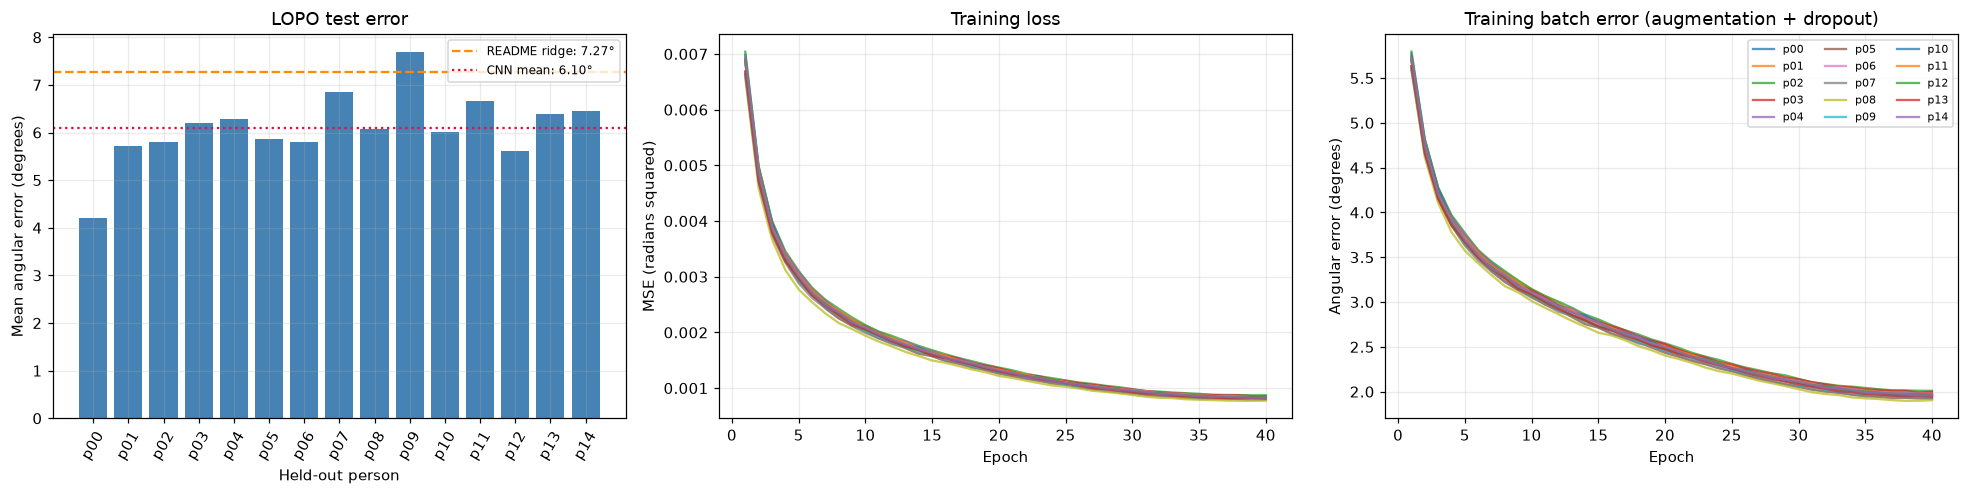

결과 파일: /Users/parkdongjun/Desktop/3-2/딥러닝/gaze_estimation/outputs/gaze_numpy/2c4d85e33360cf01


In [10]:
report = RESULTS.sort_values("test_person").reset_index(drop=True)
complete = len(report) == 15 and set(report["test_person"]) == set(PERSONS)
mean_error = float(report["mean_error_deg"].mean())
table = report[["test_person", "train_samples", "test_samples",
                "mean_error_deg", "median_error_deg", "train_minutes"]].copy()
display(table.rename(columns={
    "test_person":"테스트 사람", "train_samples":"학습 개수", "test_samples":"테스트 개수",
    "mean_error_deg":"평균 각도 오차(°)", "median_error_deg":"중앙값 오차(°)",
    "train_minutes":"학습 및 평가 시간(분)",
}).round(3))
if complete:
    print(f"최종 성능: 15-fold 평균 각도 오차 = {mean_error:.3f}° (작을수록 좋음)")
    print(f"fold 사이 표준편차 = {report['mean_error_deg'].std(ddof=0):.3f}°")
else:
    print(f"주의: {len(report)}/15 fold만 완료. 현재 평균 {mean_error:.3f}°는 최종 성능이 아닙니다.")

# README 형식의 가로 표
wide = pd.DataFrame([{
    **dict(zip(report["test_person"], report["mean_error_deg"])),
    ("평균" if complete else "부분 평균"):mean_error,
}], index=["각도 오차 (°)"])
display(wide.round(3))
atomic_csv(RUN_DIR / "report_lopo.csv", wide.rename_axis("metric").reset_index())
atomic_json(RUN_DIR / "summary.json", {
    "complete_15_folds":complete, "folds":report["test_person"].tolist(),
    "mean_error_deg":mean_error,
    "fold_std_deg":float(report["mean_error_deg"].std(ddof=0)),
    "metric":"3D angular error in degrees; lower is better",
})

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
axes[0].bar(report["test_person"], report["mean_error_deg"], color="steelblue")
axes[0].axhline(7.27, color="darkorange", linestyle="--", label="README ridge: 7.27°")
axes[0].axhline(mean_error, color="crimson", linestyle=":", label=f"CNN mean: {mean_error:.2f}°")
axes[0].set(title="LOPO test error" if complete else "Partial LOPO test error",
            xlabel="Held-out person", ylabel="Mean angular error (degrees)")
axes[0].tick_params(axis="x", rotation=60)
axes[0].legend(fontsize=8)
for person in report["test_person"]:
    hist = pd.read_csv(RUN_DIR / person / "history.csv")
    axes[1].plot(hist["epoch"], hist["train_mse_rad2"], label=person, alpha=0.75)
    axes[2].plot(hist["epoch"], hist["train_batch_error_deg"], label=person, alpha=0.75)
axes[1].set(title="Training loss", xlabel="Epoch", ylabel="MSE (radians squared)")
axes[2].set(title="Training batch error (augmentation + dropout)",
            xlabel="Epoch", ylabel="Angular error (degrees)")
axes[2].legend(ncol=3, fontsize=7)
plt.tight_layout()
fig.savefig(RUN_DIR / "lopo_results.png", bbox_inches="tight")
plt.show()
print("결과 파일:", RUN_DIR)


## 11. 저장한 모델로 예측 예시를 확인하는 셀
선택한 사람을 **학습에서 제외한 모델**을 불러와 눈 이미지, 정답, 예측값을 함께 표시합니다.
산점도에서 점이 대각선에 가까울수록 예측이 정답과 가깝습니다.
이 셀은 결과 확인용이며, 테스트 결과로 모델을 다시 선택하거나 학습하지 않습니다.


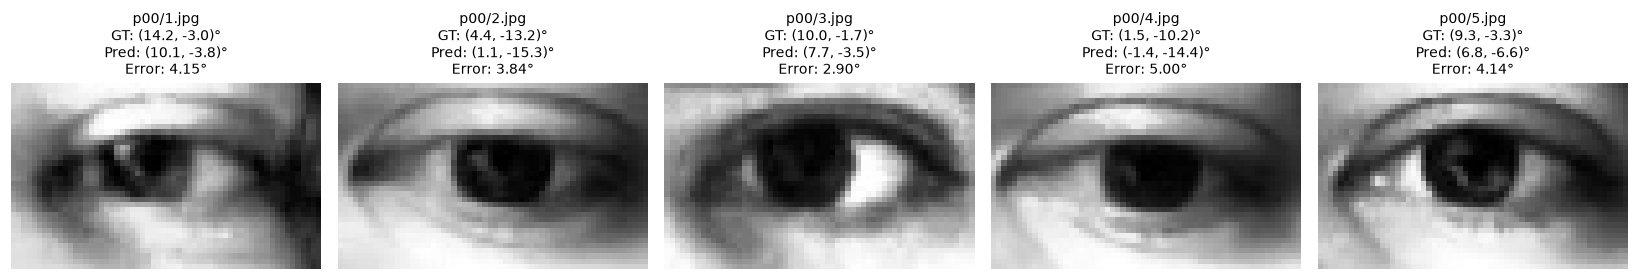

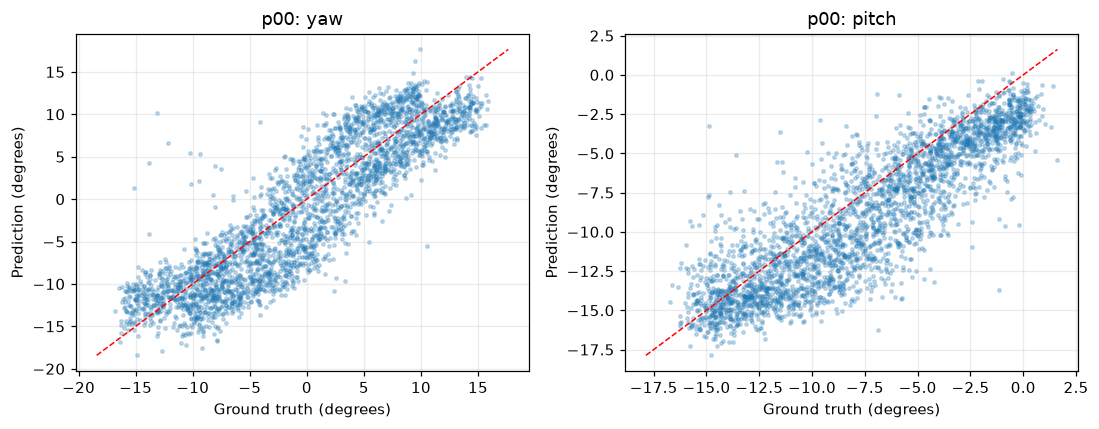

In [11]:
EXAMPLE_PERSON = report["test_person"].iloc[0]
saved_model, saved_stats, saved_meta = load_model(RUN_DIR / EXAMPLE_PERSON / "model.npz")
assert saved_meta["test_person"] == EXAMPLE_PERSON
assert EXAMPLE_PERSON not in saved_meta["train_people"]
example_idx = np.flatnonzero(DATA["persons"] == EXAMPLE_PERSON)[:5]
example_pred = predict(saved_model, DATA, example_idx, saved_stats, CFG["batch_size"])
example_gt = DATA["gazes"][example_idx]
example_errors = angular_error(example_pred, example_gt)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, idx, pred, gt, err in zip(axes, example_idx, example_pred, example_gt, example_errors):
    ax.imshow(DATA["images"][idx, 0], cmap="gray", vmin=0, vmax=255)
    pred_deg, gt_deg = np.degrees(pred), np.degrees(gt)
    ax.set_title(f"{DATA['names'][idx]}\n"
                 f"GT: ({gt_deg[0]:.1f}, {gt_deg[1]:.1f})°\n"
                 f"Pred: ({pred_deg[0]:.1f}, {pred_deg[1]:.1f})°\nError: {err:.2f}°", fontsize=9)
    ax.axis("off")
plt.tight_layout()
fig.savefig(RUN_DIR / "prediction_examples.png", bbox_inches="tight")
plt.show()

predictions = pd.read_csv(RUN_DIR / EXAMPLE_PERSON / "predictions.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, angle in zip(axes, ("yaw", "pitch")):
    gt = np.degrees(predictions[f"gt_{angle}_rad"].to_numpy())
    pred = np.degrees(predictions[f"pred_{angle}_rad"].to_numpy())
    limits = [min(gt.min(), pred.min()), max(gt.max(), pred.max())]
    ax.scatter(gt, pred, s=5, alpha=0.25)
    ax.plot(limits, limits, "r--", linewidth=1)
    ax.set(title=f"{EXAMPLE_PERSON}: {angle}", xlabel="Ground truth (degrees)",
           ylabel="Prediction (degrees)")
plt.tight_layout()
fig.savefig(RUN_DIR / "prediction_scatter.png", bbox_inches="tight")
plt.show()
del saved_model


### 결과 해석
- **학습 MSE 감소**: 학습 데이터의 정답에 점점 가까워진다는 뜻입니다.
- **테스트 각도 오차 감소**: 처음 보는 사람의 시선을 더 잘 추정한다는 뜻입니다.
- 실제 성능은 15-fold 실행 후 판단합니다. 분류 문제가 아니므로 정확도(%) 대신 각도 오차(°)를 보고합니다.
- 모델 구조는 눈 이미지 CNN 특징과 head pose를 결합하는 방식을 참고했고, 학습 계산은 NumPy로 직접 구현했습니다.
- 하이퍼파라미터를 비교해야 한다면 테스트 사람을 제외한 14명 안에서 별도의 사람 단위 검증을 진행해야 합니다.
- 코드나 설정을 수정했다면 커널을 재시작하고 위에서부터 다시 실행하세요.
